<a href="https://colab.research.google.com/github/bioinformaticswithday/insect-species-identification/blob/main/01_Molecular_Species_Identification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01. Molecular Species Identification

## 1. Install Python Libraries
- Biopython: Reading and analyzing DNA sequences.
- Pandas: Processing and organizing data into tables.
- Matplotlib: Creating data visualizations.

In [ ]:
%pip install -q biopython pandas matplotlib

## 2. Import Libraries & Setup Project

### 2.1 Import Python Libraries

In [ ]:

import Bio
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("Biopython version:", Bio.__version__)
print("Pandas version:", pd.__version__)
print("All libraries imported successfully!")

Biopython version: 1.88
Pandas version: 2.2.3
All libraries imported successfully!



### 2.2 Connect Google Drive

Google Drive used for saving dataset,
script, & result

In [ ]:

from google.colab import drive
drive.mount("/content/drive")
print("Google Drive connected successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected successfully!



### 2.3 Create Project Directory

Directory structure:
- data/: raw DNA sequence data.
- scripts/: Python analysis scripts.
- results/: analysis outputs and figures.


In [ ]:

project_dir = Path(
    "/content/drive/MyDrive/"
    "Bioinformatics_Portfolio/"
    "Molecular_Species_Identification"
)

folders = ["data", "scripts", "results"]

for folder in folders:
    (project_dir / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Project directory created!")
print("Location:", project_dir)

for folder in folders:
    print("✓", folder)


Project directory created!
Location: /content/drive/MyDrive/Bioinformatics_Portfolio/Molecular_Species_Identification
✓ data
✓ scripts
✓ results



## 3. Query DNA Sequence Input and Validation

### 3.1 Import Query DNA Sequence

**Objective:**
Import an unknown insect mitochondrial COI
sequence in FASTA format for molecular
species identification.

**Methods:**
- Upload the query FASTA file.
- Read the sequence using Biopython.
- Verify sequence ID and length.
- Prepare the query for downstream analysis.


In [ ]:

from Bio import SeqIO

# Define query FASTA path
query_file = project_dir / "data" / "query_coi.fasta"

# Read sequence directly from Google Drive
sequence = SeqIO.read(query_file, "fasta")

print("=== QUERY SEQUENCE INFORMATION ===")
print("Sequence ID:", sequence.id)
print("Length:", len(sequence.seq), "bp")
print("Query loaded successfully!")

=== QUERY SEQUENCE INFORMATION ===
Sequence ID: Unknown_Insect_01
Length: 638 bp
Query loaded successfully!



### 3.2 Query Sequence Inspection

**Objective:**
Inspect the uploaded COI sequence before
molecular species identification.

**Methods:**
- Verify sequence length.
- Examine the first and last 100 nucleotides.
- Check for unexpected characters.


In [ ]:

# Convert sequence to uppercase
dna = str(sequence.seq).upper()

# Validate DNA characters
valid_bases = set("ACGTRYSWKMBDHVN")

invalid_bases = sorted(set(dna) - valid_bases)

print("=== QUERY DNA INSPECTION ===")
print("Sequence ID:", sequence.id)
print("Length:", len(dna), "bp")

print("\nFirst 100 nucleotides:")
print(dna[:100])

print("\nLast 100 nucleotides:")
print(dna[-100:])

print("\nInvalid characters:", invalid_bases)

if len(dna) == 0 or invalid_bases:
    raise ValueError("FASTA sequence requires inspection")

print("\nFASTA sequence check passed!")


=== QUERY DNA INSPECTION ===
Sequence ID: Unknown_Insect_01
Length: 638 bp

First 100 nucleotides:
GCAGGGATAGTAGGTACTTCTTTAAGTTTATTAATTCGAGCTGAATTAGGGACTCCAGGATCTTTAATTGGAGATGATCAAATTTATAATACTATTGTAA

Last 100 nucleotides:
CTATTACTATATTACTTACTGATCGAAATTTAAATACATCATTTTTCGATCCTGCAGGTGGAGGTGATCCTATTCTTTATCAACATTTATTTTGATTTTT

Invalid characters: []

FASTA sequence check passed!



## 4. Sequence Quality Assessment

### 4.1 Nucleotide Composition Analysis

**Objective:**
Evaluate the basic characteristics of the mitochondrial
COI sequence of Spodoptera frugiperda.

**Parameters:**
- Sequence length (bp)
- Adenine (A) count
- Thymine (T) count
- Guanine (G) count
- Cytosine (C) count
- GC content (%)
- AT content (%)
- Ambiguous nucleotides

This analysis provides preliminary sequence
characterization before BLAST identification
and phylogenetic analysis.


In [ ]:

from collections import Counter

# Count nucleotides
counts = Counter(dna)

A = counts["A"]
T = counts["T"]
G = counts["G"]
C = counts["C"]

length = len(dna)

gc_content = (G + C) / length * 100
at_content = (A + T) / length * 100

ambiguous = sum(
    count for base, count in counts.items()
    if base not in "ATGC"
)

print("=== SEQUENCE ASSESSMENT ===")
print("Sequence ID:", sequence.id)
print("Sequence length:", length, "bp")
print("Adenine (A):", A)
print("Thymine (T):", T)
print("Guanine (G):", G)
print("Cytosine (C):", C)
print(f"GC content: {gc_content:.2f}%")
print(f"AT content: {at_content:.2f}%")
print("Ambiguous bases:", ambiguous)

=== SEQUENCE ASSESSMENT ===
Sequence ID: Unknown_Insect_01
Sequence length: 638 bp
Adenine (A): 181
Thymine (T): 265
Guanine (G): 93
Cytosine (C): 99
GC content: 30.09%
AT content: 69.91%
Ambiguous bases: 0



### 4.2 Nucleotide Composition Visualization

**Objective:**
Visualize the nucleotide composition of the
Spodoptera frugiperda mitochondrial COI sequence.

A bar chart is generated to compare the
frequency of adenine, thymine, guanine,
and cytosine.

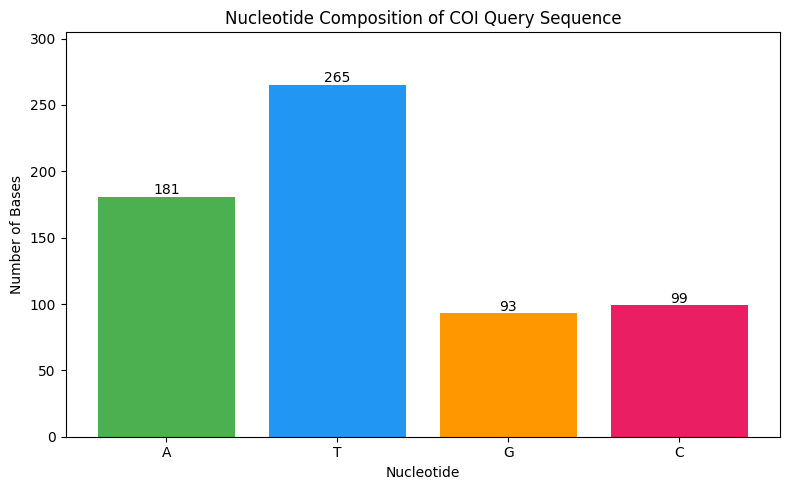

Nucleotide composition figure saved!


In [ ]:

import matplotlib.pyplot as plt

# Prepare nucleotide composition data
nucleotides = ["A", "T", "G", "C"]
values = [A, T, G, C]

# Create bar chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    nucleotides,
    values,
    color=["#4CAF50", "#2196F3", "#FF9800", "#E91E63"]
)

# Add nucleotide counts above each bar
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 2,
        str(int(height)),
        ha="center"
    )

# Chart labels
plt.title("Nucleotide Composition of COI Query Sequence")
plt.xlabel("Nucleotide")
plt.ylabel("Number of Bases")

plt.ylim(0, max(values) * 1.15)
plt.tight_layout()

# Save figure
plt.savefig(
    project_dir / "results/nucleotide_composition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Nucleotide composition figure saved!")



### 4.3 Sequence Summary Table

**Objective:**
Create a reproducible summary table containing
sequence length, nucleotide counts, GC content,
AT content, and ambiguous bases.

The results are exported as a CSV file
for subsequent analysis and documentation.

In [ ]:

import pandas as pd

# Create sequence summary table
summary = pd.DataFrame([{
    "Sequence_ID": sequence.id,
    "Length_bp": length,
    "A": A,
    "T": T,
    "G": G,
    "C": C,
    "GC_Content_Percent": round(gc_content, 2),
    "AT_Content_Percent": round(at_content, 2),
    "Ambiguous_Bases": ambiguous
}])

# Display results
print("=== COI SEQUENCE SUMMARY ===")
display(summary)

# Save table as CSV
summary.to_csv(
    project_dir / "results/sequence_summary.csv",
    index=False
)

print("Sequence summary saved successfully!")


=== COI SEQUENCE SUMMARY ===


,Sequence_ID,Length_bp,A,T,G,C,GC_Content_Percent,AT_Content_Percent,Ambiguous_Bases
0,Unknown_Insect_01,638,181,265,93,99,30.09,69.91,0


Sequence summary saved successfully!



## 5. Molecular Species Identification Using BLASTn

### 5.1 Query Sequence Preparation

**Objective:**
Prepare the uploaded mitochondrial COI sequence
for species identification using NCBI BLASTn.

**Methods:**
- Retrieve the uploaded query sequence.
- Verify its FASTA format.
- Prepare the sequence for BLASTn analysis.

**Query Information:**
- Sequence ID: Unknown_Insect_01
- Gene: Cytochrome c oxidase subunit I (COI)
- Sequence length: 638 bp

**Note:**
The query is a simulated unknown sequence
derived from GenBank accession MF197868.1.


In [ ]:

from Bio import SeqIO
from google.colab import files

# Read the uploaded query sequence
query_file = project_dir / "data" / "query_coi.fasta"

query = SeqIO.read(query_file, "fasta")

print("=== BLAST QUERY INFORMATION ===")
print("Query ID:", query.id)
print("Sequence length:", len(query.seq), "bp")
print("Sequence ready for BLASTn!")

# Download FASTA for NCBI BLAST upload
files.download(str(query_file))


=== BLAST QUERY INFORMATION ===
Query ID: Unknown_Insect_01
Sequence length: 638 bp
Sequence ready for BLASTn!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


### 5.5 BLAST Results Analysis Using Python

**Objective:**
Analyze BLASTn results to identify the most
similar reference sequences to the unknown
insect COI query.

**Methods:**
- Import the BLAST hit table (CSV).
- Assign column names.
- Examine sequence similarity.
- Identify the best matching references.

**Expected Output:**
A table containing BLAST sequence similarity
results for molecular species identification.


In [ ]:

import pandas as pd
from google.colab import files
from io import BytesIO

# Upload BLAST Hit Table CSV
uploaded = files.upload()
filename = next(iter(uploaded))

# Column names for BLAST tabular output
columns = [
    "Query_ID",
    "Subject_ID",
    "Percent_Identity",
    "Alignment_Length",
    "Mismatches",
    "Gap_Opens",
    "Query_Start",
    "Query_End",
    "Subject_Start",
    "Subject_End",
    "E_Value",
    "Bit_Score"
]

# Read BLAST CSV without header
blast = pd.read_csv(
    BytesIO(uploaded[filename]),
    header=None,
    names=columns
)

print("=== BLAST RESULTS ===")
print("Total BLAST hits:", len(blast))

display(blast.head(10))

Saving DPB2YK3J014-Alignment-HitTable.csv to DPB2YK3J014-Alignment-HitTable (3).csv
=== BLAST RESULTS ===
Total BLAST hits: 100


,Query_ID,Subject_ID,Percent_Identity,Alignment_Length,Mismatches,Gap_Opens,Query_Start,Query_End,Subject_Start,Subject_End,E_Value,Bit_Score
0,Unknown_Insect_01,OR347321.1,100.0,638,0,0,1,638,1529,2166,0.0,1179
1,Unknown_Insect_01,OR347314.1,100.0,638,0,0,1,638,1529,2166,0.0,1179
2,Unknown_Insect_01,OR347423.1,100.0,638,0,0,1,638,1529,2166,0.0,1179
3,Unknown_Insect_01,OR347315.1,100.0,638,0,0,1,638,1529,2166,0.0,1179
4,Unknown_Insect_01,OR347300.1,100.0,638,0,0,1,638,1529,2166,0.0,1179
5,Unknown_Insect_01,OR347298.1,100.0,638,0,0,1,638,1529,2166,0.0,1179
6,Unknown_Insect_01,OR347227.1,100.0,638,0,0,1,638,1529,2166,0.0,1179
7,Unknown_Insect_01,OR347219.1,100.0,638,0,0,1,638,1529,2166,0.0,1179
8,Unknown_Insect_01,OR347221.1,100.0,638,0,0,1,638,1529,2166,0.0,1179
9,Unknown_Insect_01,OR347204.1,100.0,638,0,0,1,638,1528,2165,0.0,1179



### 5.6 Best BLAST Match Identification

**Objective:**
Identify the most similar reference sequences
based on sequence identity, query coverage,
and alignment bit score.

**Methods:**
- Calculate query coverage.
- Sort BLAST hits by similarity.
- Display the top five reference matches.
- Export the results as a CSV file.


In [ ]:

# Convert relevant columns to numeric
numeric_columns = [
    "Percent_Identity",
    "Alignment_Length",
    "Query_Start",
    "Query_End",
    "E_Value",
    "Bit_Score"
]

blast[numeric_columns] = blast[numeric_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

# Calculate query coverage
query_length = len(sequence.seq)

blast["Query_Coverage"] = (
    (blast["Query_End"] - blast["Query_Start"]).abs() + 1
) / query_length * 100

# Sort by best matches
best_hits = blast.sort_values(
    by=["Bit_Score", "Query_Coverage",
        "Percent_Identity"],
    ascending=False
)

# Display top five
top5 = best_hits.head(5)

print("=== TOP 5 BLAST MATCHES ===")

display(
    top5[
        [
            "Subject_ID",
            "Percent_Identity",
            "Query_Coverage",
            "E_Value",
            "Bit_Score"
        ]
    ].round(2)
)

# Save results
top5.to_csv(
    project_dir / "results/blast_top5_matches.csv",
    index=False
)

print("Top 5 BLAST matches saved!")


=== TOP 5 BLAST MATCHES ===


,Subject_ID,Percent_Identity,Query_Coverage,E_Value,Bit_Score
0,OR347321.1,100.0,100.0,0.0,1179
1,OR347314.1,100.0,100.0,0.0,1179
2,OR347423.1,100.0,100.0,0.0,1179
3,OR347315.1,100.0,100.0,0.0,1179
4,OR347300.1,100.0,100.0,0.0,1179


Top 5 BLAST matches saved!



### 5.7 Species Identification Summary

**Objective:**
Identify the candidate insect species by retrieving
taxonomic information from the top BLAST matches.

**Methods:**
- Retrieve reference metadata from NCBI GenBank.
- Extract scientific names.
- Combine taxonomic information with BLAST results.
- Generate a species identification summary.

**Expected Output:**
A table showing the top BLAST matches and their
corresponding scientific names.


In [ ]:

from Bio import Entrez, SeqIO
import pandas as pd

# Use the NCBI email configured earlier
# Entrez.email should contain your valid email

accessions = top5["Subject_ID"].tolist()

# Retrieve taxonomic information
with Entrez.efetch(
    db="nuccore",
    id=",".join(accessions),
    rettype="gb",
    retmode="text"
) as handle:
    records = list(SeqIO.parse(handle, "genbank"))

# Build accession-to-species mapping
species_lookup = {
    rec.id: rec.annotations.get("organism", "Unknown")
    for rec in records
}

# Add scientific names
identification_table = top5.copy()

identification_table["Scientific_Name"] = (
    identification_table["Subject_ID"]
    .map(species_lookup)
)

# Display relevant columns
print("=== SPECIES IDENTIFICATION SUMMARY ===")

display(
    identification_table[
        [
            "Subject_ID",
            "Scientific_Name",
            "Percent_Identity",
            "Query_Coverage",
            "E_Value"
        ]
    ]
)

# Save results
identification_table.to_csv(
    project_dir / "results/species_identification_summary.csv",
    index=False
)

print("Species identification summary saved!")


=== SPECIES IDENTIFICATION SUMMARY ===


,Subject_ID,Scientific_Name,Percent_Identity,Query_Coverage,E_Value
0,OR347321.1,Spodoptera frugiperda,100.0,100.0,0.0
1,OR347314.1,Spodoptera frugiperda,100.0,100.0,0.0
2,OR347423.1,Spodoptera frugiperda,100.0,100.0,0.0
3,OR347315.1,Spodoptera frugiperda,100.0,100.0,0.0
4,OR347300.1,Spodoptera frugiperda,100.0,100.0,0.0


Species identification summary saved!



### 5.8 Biological Interpretation and Final Conclusion

**Results:**

The mitochondrial COI query sequence (638 bp) was analyzed using NCBI BLASTn for molecular species identification.

The five highest-ranking BLAST matches were identified as *Spodoptera frugiperda*, with 100% sequence identity and 100% query coverage.

The BLAST results indicate that the query sequence is identical to multiple *S. frugiperda* reference sequences across the aligned COI region.

**Conclusion:**

Based on the BLASTn results, the query sequence was identified as a strong candidate for *Spodoptera frugiperda*.

The analysis demonstrates the application of mitochondrial COI DNA barcoding, NCBI BLASTn, Biopython, and Pandas for reference-based molecular species identification.

**Limitations:**

This project used a publicly available GenBank COI sequence (MF197868.1) as a simulated unknown sample. Therefore, the analysis does not represent the identification of a newly sequenced specimen.

Furthermore, high sequence similarity alone does not guarantee unique species identification without comparison against closely related species.


In [ ]:

conclusion = """
MOLECULAR SPECIES IDENTIFICATION

Query: Unknown_Insect_01
Original accession: MF197868.1
Sequence length: 638 bp
Gene: Mitochondrial COI

Identification result:
Candidate species: Spodoptera frugiperda
Top BLAST identity: 100%
Query coverage: 100%

Conclusion:
The COI query matched multiple GenBank references
annotated as Spodoptera frugiperda.

This is a simulated identification using a
publicly available reference sequence.

Further comparisons with closely related species
are recommended for independent validation.
"""

output = project_dir / "results" / "conclusion.txt"

output.write_text(conclusion, encoding="utf-8")

print("Project conclusion saved successfully!")


Project conclusion saved successfully!
